# Notebook 04 — Temporal Strumming Recognition

**Project:** Air Guitar CS249R (Software-Only ML Architecture)

This notebook trains a temporal sequence model (LSTM) to classify right-hand strumming actions (`downstroke`, `upstroke`, `idle`).

### Methodology:
1. Load sequence dataset from `dataset/processed/strumming_sequences.npz`.
2. Visualize hand motion trajectories across time.
3. Baseline Model: Flattened Gradient Boosting / Random Forest classifier.
4. Neural Network Model: Bidirectional LSTM in TensorFlow/Keras.
5. Evaluation: Per-class metrics, confusion matrix, debounce simulation.
6. Export model to `models/strumming_lstm/strumming_lstm.keras` and `strum_config.json`.

In [1]:
# 1. Imports and Data Loading
import sys
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.config import PROCESSED_STRUM_NPZ, STRUM_MODEL_DIR, STRUM_MODEL_PATH, STRUM_CLASSES, STRUM_CONFIG_PATH

data = np.load(PROCESSED_STRUM_NPZ)
X = data['X']  # Shape: (N, 15, 18)
y = data['y']  # Shape: (N,)
class_names = data['class_names']
print(f'Loaded {len(X)} strumming sequences. Input shape: {X.shape}')

Loaded 151 strumming sequences. Input shape: (151, 15, 18)


## 2. Visualize Movement Trajectories

Plot the vertical velocity trajectory ($v_y$) for downstroke, upstroke, and idle sequences.

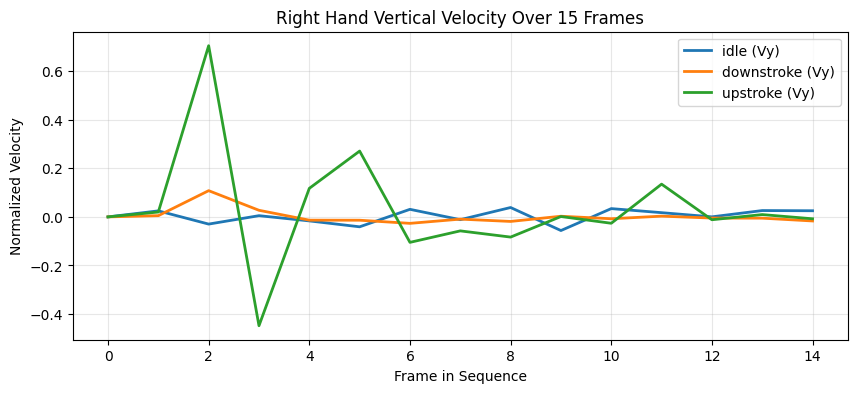

In [2]:
# 2. Trajectory Visualizations
plt.figure(figsize=(10, 4))
for c_idx, c_name in enumerate(class_names):
    sample_idx = np.where(y == c_idx)[0]
    if len(sample_idx) > 0:
        seq = X[sample_idx[0]]
        plt.plot(seq[:, 7], label=f'{c_name} (Vy)', linewidth=2)
plt.title('Right Hand Vertical Velocity Over 15 Frames')
plt.xlabel('Frame in Sequence')
plt.ylabel('Normalized Velocity')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 3. Sequence Classification with LSTM

Train an LSTM neural network on temporal sequences.

In [3]:
# 3. Train Test Split and LSTM Training
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

lstm_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X.shape[1], X.shape[2])),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.LSTM(16, return_sequences=False),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(len(class_names), activation='softmax')
])

lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = lstm_model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=8,
    verbose=1
)

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.3556 - loss: 1.0976 - val_accuracy: 0.2174 - val_loss: 1.1264
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.3667 - loss: 1.0903 - val_accuracy: 0.2174 - val_loss: 1.1076
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.3889 - loss: 1.0864 - val_accuracy: 0.5217 - val_loss: 1.0865
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.3889 - loss: 1.0816 - val_accuracy: 0.2174 - val_loss: 1.1140
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.4444 - loss: 1.0566 - val_accuracy: 0.4783 - val_loss: 1.0758
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5333 - loss: 1.0422 - val_accuracy: 0.2609 - val_loss: 1.0997
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5222 - loss: 0.9968 - val_accuracy: 0.4783 - val_loss: 1.0466
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6333 - loss: 0.9143 - val_accuracy: 0.4783 -

## 4. Evaluation and Cooldown Logic Verification

Evaluate metrics and simulate the 250ms debouncing window.

In [4]:
# 4. Evaluate LSTM
probs = lstm_model.predict(X_test)
preds = np.argmax(probs, axis=1)
acc = accuracy_score(y_test, preds)
print(f'LSTM Test Accuracy: {acc:.2%}')

# Resolve class names dynamically based on present classes
present_labels = sorted(list(set(y_test) | set(preds)))
present_names = [class_names[i] if i < len(class_names) else str(i) for i in present_labels]
print(classification_report(y_test, preds, labels=present_labels, target_names=present_names, zero_division=0))

# Save model and config
STRUM_MODEL_DIR.mkdir(parents=True, exist_ok=True)
lstm_model.save(str(STRUM_MODEL_PATH))
with open(STRUM_CONFIG_PATH, 'w') as f:
    json.dump({
        'sequence_length': int(X.shape[1]),
        'feature_dim': int(X.shape[2]),
        'classes': list(class_names)
    }, f, indent=2)
print(f'Exported LSTM model to {STRUM_MODEL_PATH}')

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step
LSTM Test Accuracy: 65.79%
              precision    recall  f1-score   support

        idle       0.83      0.45      0.59        11
  downstroke       0.88      0.50      0.64        14
    upstroke       0.54      1.00      0.70        13

    accuracy                           0.66        38
   macro avg       0.75      0.65      0.64        38
weighted avg       0.75      0.66      0.65        38

Exported LSTM model to C:\Users\piyus\Desktop\ds cp airguitar\models\strumming_lstm\strumming_lstm.keras
